# Micrograd - Initial Concepts

Intro. Understanding basic concepts.

---
*00:08:08 derivative of a simple function with one input*

In [271]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [272]:
def f(x):
    return 3 * x**2 - 4 * x + 5

In [273]:
f(3)

20

In [274]:
xs = np.arange(-5, 5, 0.25)
xs

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

In [275]:
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

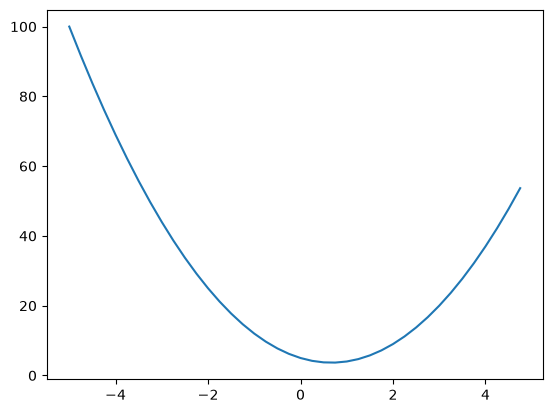

In [276]:
plt.plot(xs, ys)

In [277]:
# derivative
h = 0.0001
x = 3.0
print(f"{f(x + h)} : y changes when x is sligtly changed")
print(f"{f(x + h) - f(x)} : with how much y changed")
print(f"{(f(x + h) - f(x)) / h} : the slope")  # slope

20.001400030000006 : y changes when x is sligtly changed
0.0014000300000063248 : with how much y changed
14.000300000063248 : the slope


In [278]:
# let's get more complex and find the derivative for a more complicated function (d here)
a = 2.0
b = -3.0
c = 10.0
d = a * b + c
print(d)

4.0


In [279]:
# derivative for d
h = 0.0001  # change

d1 = a * b + c
a += h
d2 = a * b + c

print("d1", d1)
print("d2", d2)

slope = (d2 - d1) / h
print("slope", slope)

d1 4.0
d2 3.999699999999999
slope -3.000000000010772


---
*00:19:09 starting the core Value object of micrograd and its visualization*

In [281]:
class Value:

    def __init__(self, data, _children=(), _op="", label=""):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward

        return out

    def __radd__(self, other):  # other + self
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward

        return out

    def __rmul__(self, other):  # other * self
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers"
        out = Value(self.data**other, (self,), f"**{other}")

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad

        out._backward = _backward

        return out

    def __truediv__(self, other):  # self / other
        return self * other**-1

    def __neg__(self):  # -self
        return self * -1

    def __sub__(self, other):  # self - other
        return self + (-other)

    def tahn(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), "tahn")

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), "exp")

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward

        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [282]:
a = Value(2.0, label="a")
b = Value(-3.0, label="b")
c = Value(10.0, label="c")

e = a * b
e.label = "e"
d = e + c
d.label = "d"

f = Value(-2.0, label="f")
L = d * f
L.label = "L"

In [283]:
d, d._prev, (a + b)._prev, d._op

(Value(data=4.0),
 {Value(data=-6.0), Value(data=10.0)},
 {Value(data=-3.0), Value(data=2.0)},
 '+')

In [284]:
from graphviz import Digraph


def trace(root):
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root, format="svg", rankdir="LR"):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ["LR", "TB"]
    nodes, edges = trace(root)
    dot = Digraph(
        format=format, graph_attr={"rankdir": rankdir}
    )  # , node_attr={'rankdir': 'TB'})

    for n in nodes:
        dot.node(
            name=str(id(n)),
            label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad),
            shape="record",
        )
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

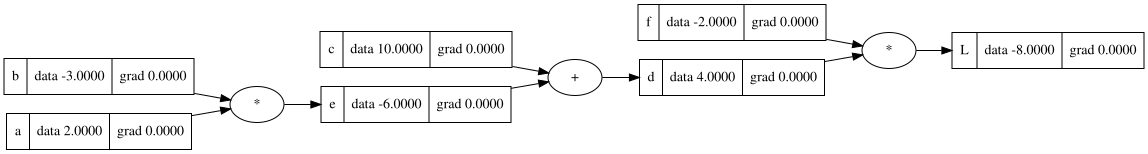

In [285]:
draw_dot(L)

---
*00:32:10 manual backpropagation example #1: simple expression*

In [286]:
# backpropagation - manually

# Formula
# dz/dx = dz/dy * dy/dx
# The backpropagation of z relative to x

# Base case for output node
L.grad = 1.0

In [287]:
# gradients for d and f

# We know L = d * f
# We want to know dL / dd
# We want to know dL / de

# dL / dd deduction - d is increased by h
# (f(x+h) - f(x)) / h
# (((d+h) * f) - (d * f)) / h
# (df + hf - df) / h
# hf / h => f

# dL / df deduction - f is increased by h
# (f(x+h) - f(x)) / h
# ((d * (f+h)) - (d * f)) / h
# (df + dh - df) / h
# dh / h => d

# dz/dx = (dz/dy) * (dy/dx)
# dL/dd = dL * (dL/dd)
d.grad = 1.0 * f.data
# dL/df = L * (dL/df)
f.grad = 1.0 * d.data

In [288]:
# gradients for c and e - the node is addition
# d = c + e - this is the f (the function)

# dd / dc = 1.0 -> deduction
# (f(x+h) - f(x)) / h - the derivative formula
# ((c+h + e) - (c + e)) / h - here c is increased with h
# (c + h + e - c - e) / h - c and e cancels each other: c-c and e-e
# h / h = 1

# dd / de = 1.0 -> deduction
# (f(x+h) - f(x)) /h
# ((c + e+h) - (c + e)) / h - here e is increased with h
# (c + e + h - c - e) / h - c end e cancels each other
# h / h = 1

# dz/dx = (dz/dy) * (dy/dx)
# dd / dc = (dL / dd) * (dd / dc)
c.grad = d.grad * 1.0
# dd / de = (dL / dd) * (dd / de)
e.grad = d.grad * 1.0

In [289]:
# gradients for a and b - node is multiplication
# same deduction as for d and f - the node is multiplication

# We know e = a * b
# We want de / da and de / db

# de / da -> deduction
# (f(x+h) - f(x)) /h
# ((a+h) * b) - (a * b)) / h
# (ab + hb - ab) / h
# hb / h -> b

# de / db -> deduction
# (f(x+h) - f(x)) /h
# (a * (b+h) - (a * b)) / h
# (ab + ah - ab) / h
# ah / h -> a

# dz/dx = (dz/dy) * (dy/dx)
# dL/da = (dL/de) * (de/da)
a.grad = e.grad * b.data
# dL/db = (dL/de) * (de/db)
b.grad = e.grad * a.data

In [290]:
# Backpropagation of L in respect to itself is 1. See lol function.
# This is the output node, so it's the base case.


# Create a function to not pollute (mess up) with notebook global scope.
# Here variables are kept in inner scope, and don't break outer scope.

# Derivative verification - increase with h any piece for testing the derivative
def lol():
    h = 0.0001

    a = Value(2.0, label="a")
    b = Value(-3.0, label="b")
    c = Value(10.0, label="c")

    e = a * b
    e.label = "e"
    d = e + c
    d.label = "d"

    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label="a")
    b = Value(-3.0, label="b")
    c = Value(10.0, label="c")
    b.data +=h

    e = a * b
    e.label = "e"
    d = e + c
    d.label = "d"

    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    # L changes, but doesn't affect itself. The derivative is 1
    # In other words, the output node doesn't affect itself, the effect is 1.
    # Try to play with different values of `h` and you'll have the same value of 1.
    print((L2 - L1) / h)


lol()

-4.000000000008441


---
*00:52:52 manual backpropagation example #2: a neuron*

In [291]:
# # inputs x1, x2
# x1 = Value(2.0, label="x1")
# x2 = Value(0.0, label="x2")
# # weights w1, w2
# w1 = Value(-3.0, label="w1")
# w2 = Value(1.0, label="w2")
# # bias of the neuron
# b = Value(6.8813735870195432, label="b")

# x1w1 = x1 * w1
# x1w1.label = "x1*w1"
# x2w2 = x2 * w2
# x2w2.label = "x2*w2"
# x1w1x2w2 = x1w1 + x2w2
# x1w1x2w2.label = "x1*w1 + x2*w2"
# n = x1w1x2w2 + b
# n.label = "n"

# o = n.tahn(); o.label='o'
# o.backward()

In [292]:
# draw_dot(o)

In [293]:
# V1. Manual backpropagation - Neuron

# # Output - base case - 1.0
# o.grad = 1.0

# # tanh derivative
# # do / dn = 1 - o**2
# n.grad = 1 - o.data**2

# # do/x1w1x2w2 derivative: do/dx1w1x2w2 = do/dn * dn/x1w1x2w2
# x1w1x2w2.grad = n.grad * 1.0
# # b derivative: do/db = do/dn * dn/db
# b.grad = n.grad * 1.0

# # do/x2w2 = do/dx1w1x2w2 * dx1w1x2w2/dx2w2
# x2w2.grad = x1w1x2w2.grad * 1.0
# # dx1w1 = do/dx1w1x2w2 * dx1w1x2w2/dx1w1
# x1w1.grad = x1w1x2w2.grad * 1.0

# # do/x2 = do/x2w2 * dx2w2/dx2
# x2.grad = x2w2.grad * w2.data
# # do/w2 = do/x2w2 * dx2w2/dw2
# w2.grad = x2w2.grad * x2.data

# # do/x1 = do/x1w1 * dx1w1/dx1
# x1.grad = x1w1.grad * w1.data
# # do/w1 = do/x1w1 * dx1w1/dw1
# w1.grad = x1w1.grad * x1.data

In [294]:
# V2. Backpropagation using backward function for each operation - Neuron

# o.grad = 1.0
# o._backward()
# n._backward()
# x1w1x2w2._backward()
# b._backward()
# x2w2._backward()
# x1w1._backward()

In [295]:
# V3. Backpropagation using backward function for the whole graph - Neuron

# We're using a topological order here.
# Topological order is a traversal mechanism there the direction goes in one way only.
# See Value.backward function.

# Initiate output grad base case
# o.backward()

In [296]:
# Adding more nodes (decomposing the tanh)

# inputs x1, x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")
# weights w1, w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias of the neuron
b = Value(6.8813735870195432, label="b")

x1w1 = x1 * w1
x1w1.label = "x1*w1"
x2w2 = x2 * w2
x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 + b
n.label = "n"

# --- changed here
e = (2 * n).exp()
o = (e - 1) / (e + 1)
o.label = "o"
# ---
o.backward()

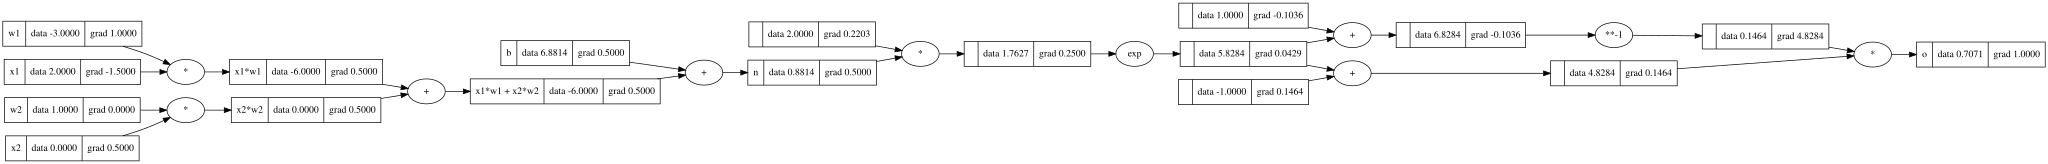

In [297]:
draw_dot(o)